In [1]:
import numpy as np
from scipy.sparse.linalg import svds
import fastplotlib as fpl
from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from itertools import product
from typing import *
from time import time
import tifffile
import h5py
from ipywidgets import HBox, VBox

Unable to find extension: VK_EXT_swapchain_colorspace
No windowing system present. Using surfaceless platform
No config found!
No config found!


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Available devices:
✅ (default) | NVIDIA A100-SXM4-40GB | DiscreteGPU | Vulkan | 535.129.03
❗ | NVIDIA A100-SXM4-40GB/PCIe/SSE2 | Unknown | OpenGL | 


In [2]:
filename = "/mnt/home/kkolar/data/astrocyte/FOV_excerpt_recording_01.tif"

In [3]:
movie = tifffile.imread(filename)

In [4]:
std = np.mean(movie, axis=0)

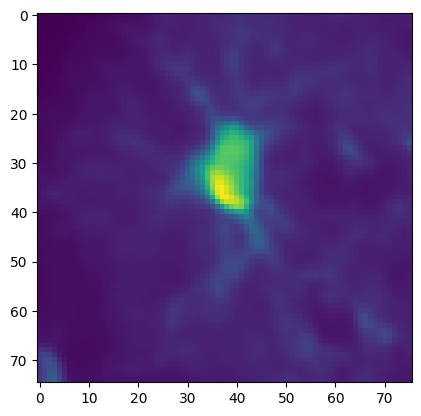

In [5]:
plt.imshow(std)

In [6]:
iw_movie = fpl.ImageWidget(movie, cmap="gnuplot2")
iw_movie.show()

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(), IpywidgetToolBar(children=(Button(icon='expand-arrows-alt'…

In [10]:
iw_movie.window_funcs = {"t": (np.mean, 25)}

In [20]:
centered = movie - movie.mean(axis=0)

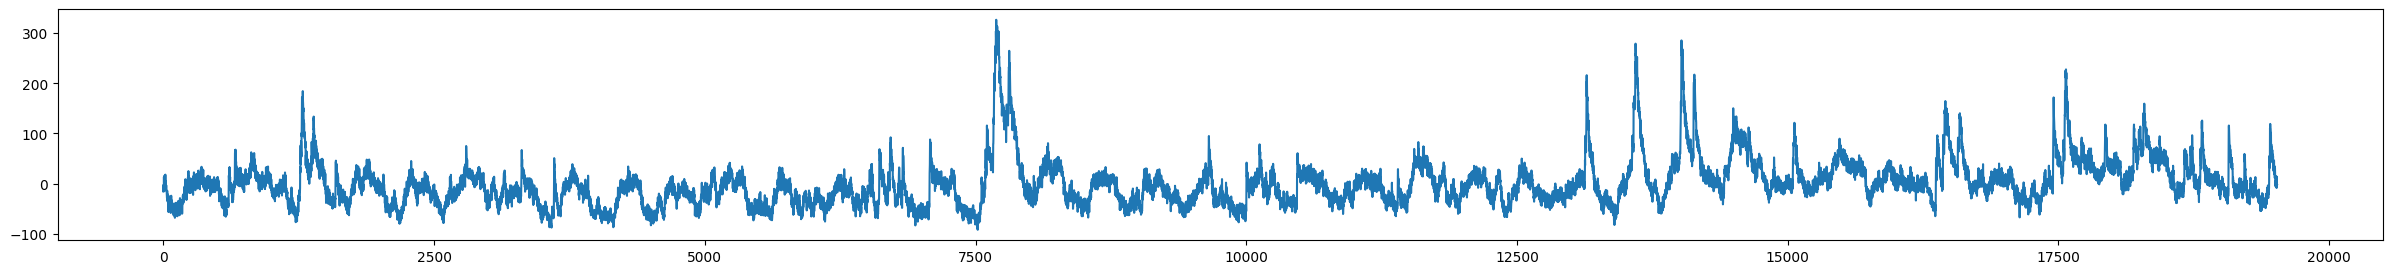

In [31]:
fig = plt.figure(figsize=(30, 3))
plt.plot(centered.mean(axis=(1, 2)))
plt.show()

In [32]:
class TdSVD:
    def __init__(
        self,
        movie: np.ndarray,
        n_time_steps: int,
        delay: int,
    ):
        self.n_time_steps = n_time_steps
        self.movie_mean = movie.mean(axis=0)
        
        frame = movie[0]
        self.xdim, self.ydim = frame.shape[0], frame.shape[1]
        
        n_pixels = self.xdim * self.ydim
        n_timepoints = movie.shape[0]
        
        self.A = np.zeros(shape=(n_pixels * n_time_steps, n_timepoints - n_time_steps), dtype=np.float32)
        A_ixs = np.zeros(n_pixels * n_time_steps)
        
        for pixel_ix, (x, y) in tqdm(enumerate(product(range(self.xdim), range(self.ydim))), total=n_pixels):
            for step in range(n_time_steps):
                self.A[(n_time_steps * pixel_ix) + step] = np.roll(movie[:, x, y], shift=-delay * step)[:-n_time_steps]

        self.k, self.U, self.S, self.V = None, None, None, None
    
    def fit(self, k=6, **kwargs):
        self.k = k
        t0 = time()
        self.U, self.S, self.V = svds(self.A, k=k, **kwargs)
        self.U = self.U[:, ::-1]
        self.S = self.S[::-1]
        self.V = self.V[::-1, :]
        t1 = time()
        print(f"svd took: {t1 - t0:.02f} sec")

    def get_spatial(self):
        """
        Returns
        -------
        np.ndarray
            [n_time_steps, k, ydim, xdim]
        """
        return np.array([self.U.reshape((self.xdim, self.ydim, self.n_time_steps, self.k))[..., i, :].transpose(2, 0, 1) for i in range(self.n_time_steps)])

In [34]:
td_svd = TdSVD(
    movie=centered[i],
    n_time_steps=n,
    delay=1,
)

100%|███████████████████████████████████████████████████████████████████████████████████████████| 2091/2091 [00:00<00:00, 5698.00it/s]


svd took: 2.76 sec


100%|███████████████████████████████████████████████████████████████████████████████████████████| 2091/2091 [00:00<00:00, 4024.74it/s]


svd took: 4.22 sec


100%|███████████████████████████████████████████████████████████████████████████████████████████| 2091/2091 [00:00<00:00, 2613.26it/s]


svd took: 6.15 sec


... (100 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████████████████| 1122/1122 [00:03<00:00, 353.81it/s]


svd took: 22.02 sec


100%|████████████████████████████████████████████████████████████████████████████████████████████| 1122/1122 [00:03<00:00, 314.62it/s]


svd took: 22.31 sec


In [46]:
spatial = td_svd.get_spatial()

In [48]:
iw_steps = fpl.ImageWidget(
    data=[spatial[step] for step in range(td_svd.n_time_steps)],
    names=[f"step-{i}" for i in range(td_svd.n_time_steps)],
    grid_plot_kwargs={"size": (1500, 400)},
    cmap="gnuplot2",
)
iw_steps.show()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

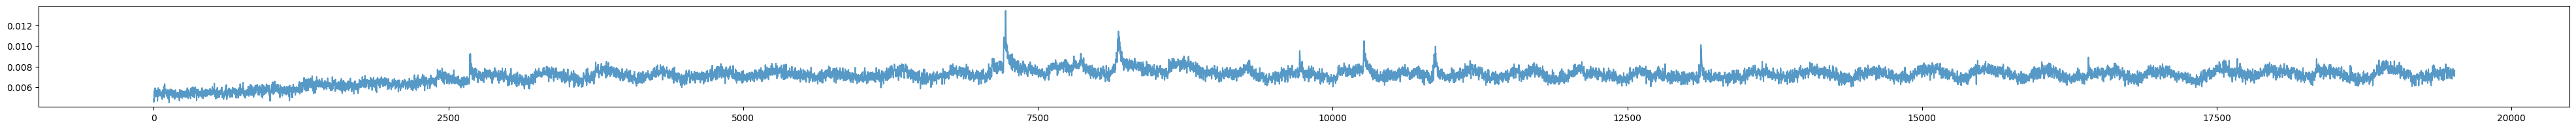

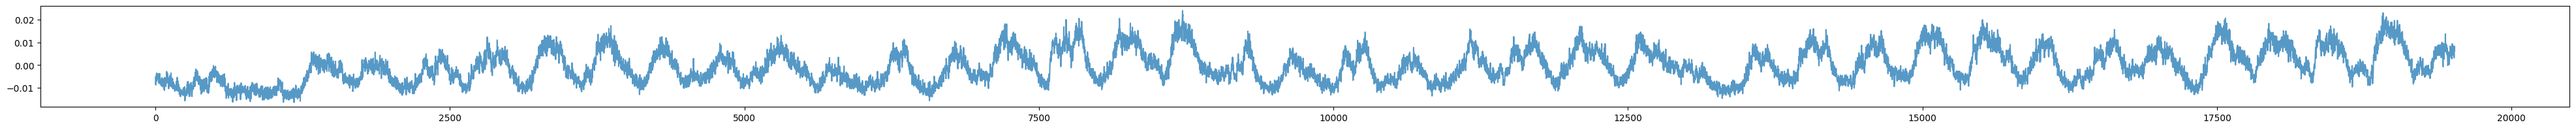

In [63]:
# fig = plt.figure(figsize=(30, 2))

for i, vi in enumerate(td_svd.V):
    fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    plt.show()
    if i == 1:
        break
    # plt.show()
# plt.legend()
plt.show()

In [72]:
centered[1].shape

(19520, 42, 43)

In [75]:
u.shape

(1892, 10)

In [84]:
selected_neuron.shape

(19520, 42, 43)

In [86]:
iw_steps = fpl.ImageWidget(
    data=[ui.reshape(selected_neuron.shape[1:]) for ui in u.T],
    grid_plot_kwargs={"size": (1500, 400)}
)
iw_steps.show()

RFBOutputContext()

/mnt/home/kkolar/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:34: UserWarning: converting float64 array to float32
  warn(f"converting {array.dtype} array to float32")


JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

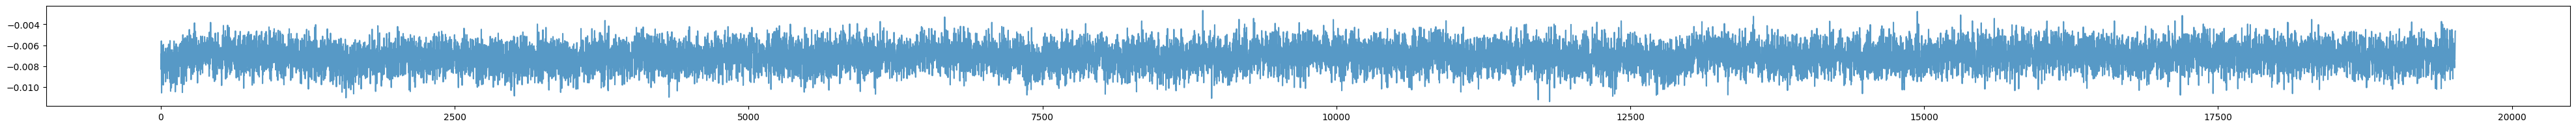

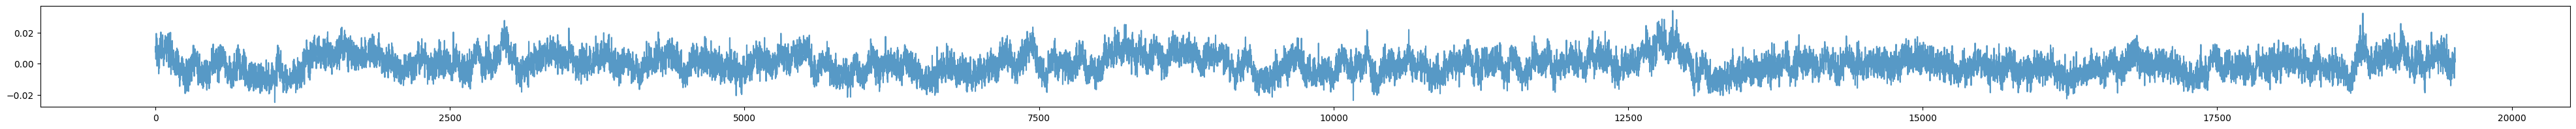

In [71]:
# fig = plt.figure(figsize=(30, 2))

for i, vi in enumerate(v):
    fig = plt.figure(figsize=(50, 2))
    plt.plot(vi, label=str(i), alpha=0.75)
    plt.show()
    if i == 1:
        break
    # plt.show()
# plt.legend()
plt.show()

In [63]:
plt.close()

In [49]:
iw_steps = fpl.ImageWidget(
    data=[spatial[:, k_step] for k_step in range(td_svd.k)],
    names=[f"step-{i}" for i in range(td_svd.k)],
    grid_plot_kwargs={"size": (1500, 400)}
)

plot_lines = fpl.Plot()
plot_lines.docks["right"].size = 70

# legend = fpl.Legend(plot_lines.docks["right"])
# for i, (vi, c) in enumerate(zip(td_svd.V, ["red", "orange", "yellow", "green", "blue", "purple"])):
#     l = plot_lines.add_line(vi, colors=c, name=f"{i}")
    # legend.add_graphic(l, label=f"{i}---")

# plot_lines.show()

iw_steps.show()
# HBox([iw_steps.widget, plot_lines.widget])

RFBOutputContext()

RFBOutputContext()

JupyterOutputContext(children=(JupyterWgpuCanvas(css_height='400px', css_width='1500px'), IpywidgetToolBar(chi…

In [78]:
u, s, v = svds(selected_neuron.reshape(selected_neuron.shape[0], selected_neuron.shape[1] * selected_neuron.shape[2]).T.astype(np.float32), k=10)

In [79]:
u = u[:, ::-1]
s = s[::-1]
v = v[::-1]

In [38]:
%matplotlib inline

# Normalized S and td S

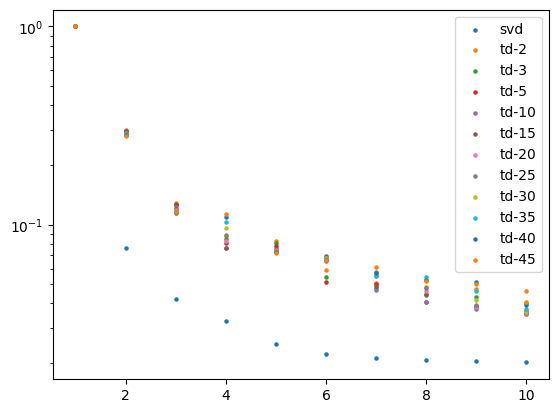

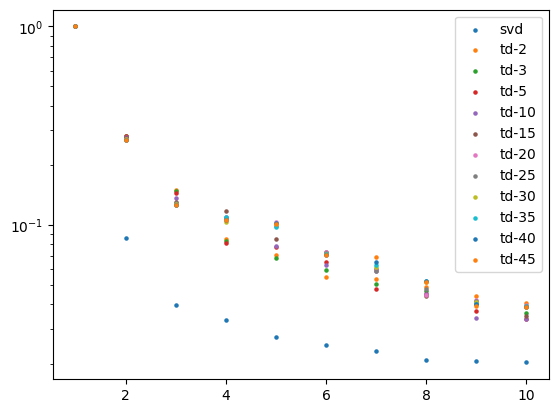

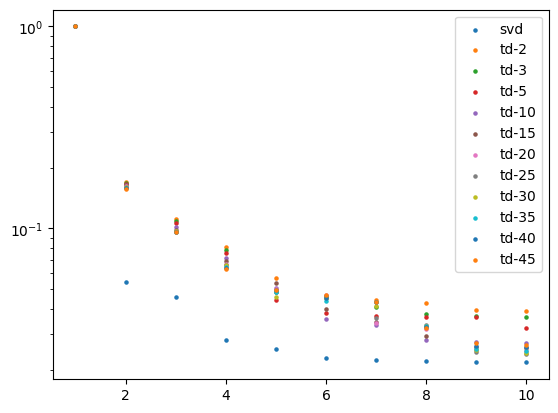

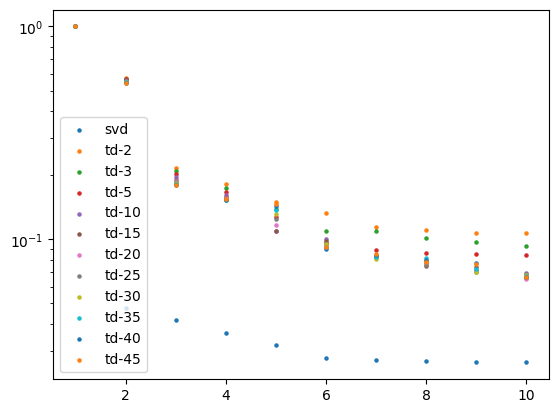

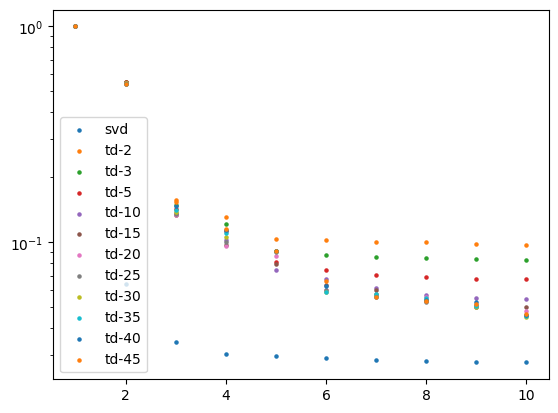

In [35]:
for neuron, neuron_td in zip(neurons, neuron_tds):
    u, s, v = svds(neuron.reshape(neuron.shape[0], neuron.shape[1] * neuron.shape[2]).T.astype(np.float32), k=10)
    u = u[:, ::-1]
    s = s[::-1]
    v = v[::-1]
    
    plt.scatter(np.arange(1, 11), s[:] / s.max(), label="svd", s=5)
    for k in sorted(neuron_td.keys()):
        td_svd = neuron_td[k]
        plt.scatter(np.arange(1, 11), td_svd.S / td_svd.S.max(), label=f"td-{k}", s=5)
        plt.yscale("log")
        plt.legend()
    plt.show()

# S and td S

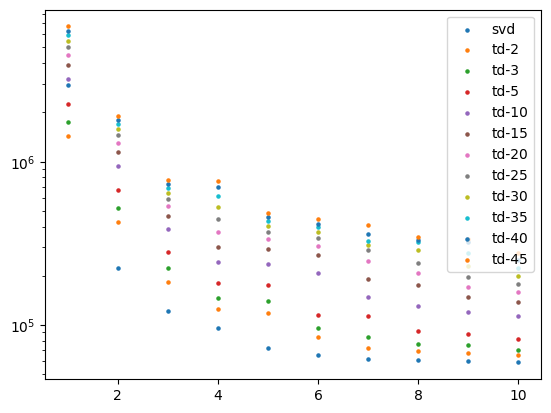

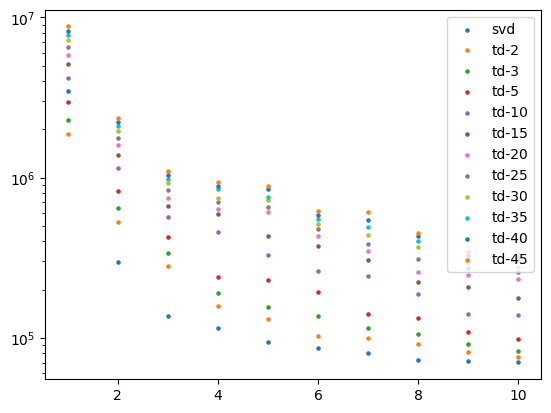

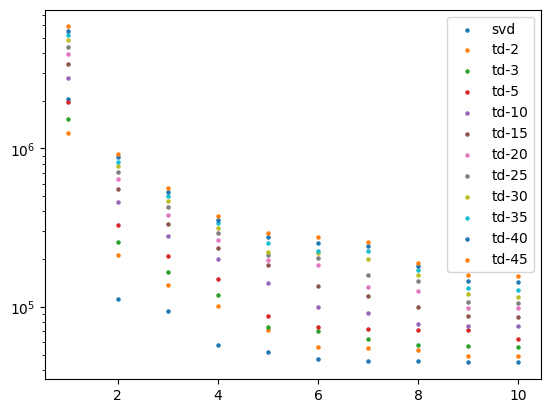

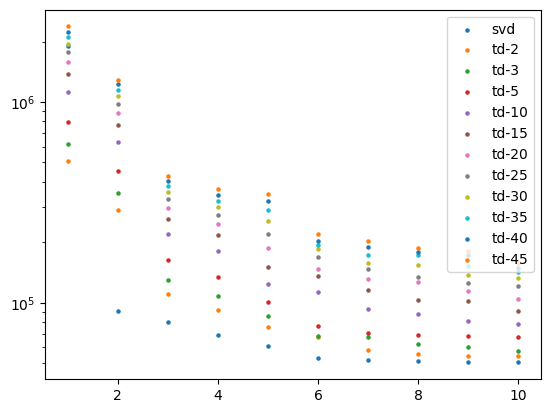

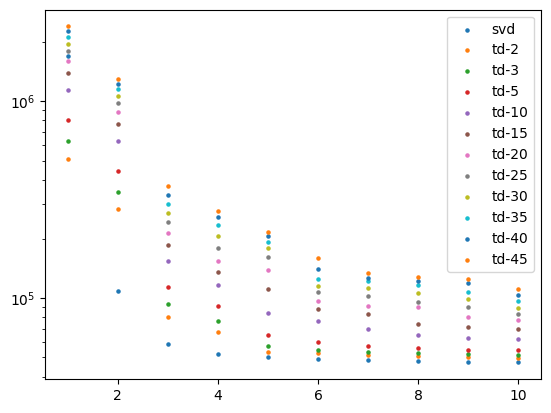

In [36]:
for neuron, neuron_td in zip(neurons, neuron_tds):
    u, s, v = svds(neuron.reshape(neuron.shape[0], neuron.shape[1] * neuron.shape[2]).T.astype(np.float32), k=10)
    u = u[:, ::-1]
    s = s[::-1]
    v = v[::-1]
    
    plt.scatter(np.arange(1, 11), s, label="svd", s=5)
    for k in sorted(neuron_td.keys()):
        td_svd = neuron_td[k]
        plt.scatter(np.arange(1, 11), td_svd.S, label=f"td-{k}", s=5)
        plt.yscale("log")
        plt.legend()
    plt.show()

In [45]:
u, s, v = svds(movie.reshape(movie.shape[0], movie.shape[1] * movie.shape[2]).T.astype(np.float32), k=10)

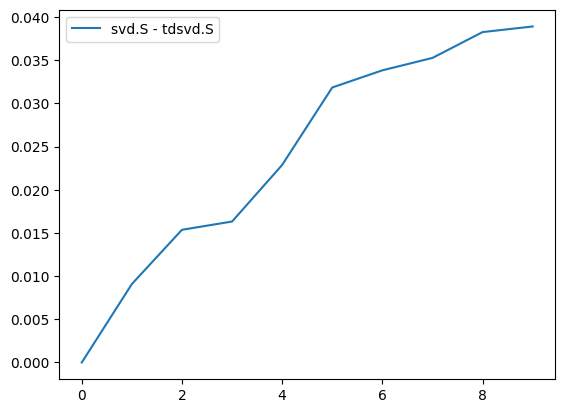

In [83]:
plt.plot((s[:] / s.max()) - (td_svd.S / td_svd.S.max()), label="svd.S - tdsvd.S")
# plt.yscale("log")
plt.legend()